NOTE: Numba will compile the parallel kernel during the first sector.

Lattice 2x2 (L=4) | Fixed Density = 1
--> Target Samples: 30 (Batched in chunks of 400)

--> Applying biases: err_min=0.005, err_max=0.007
  * T = 0.010 | Required mu (exact) = 1.2262
    -> Density evaluated (sanity check): 1.0000
    [Gamma 1] T^* (Max) = 0.765284
      -> Maximizing Sector (k, k'): (2, 2)
      -> lambda(H_sector): 9.388524
      -> log( Tr(e^{-beta H_sector}) / dim_sector ): 128.439977
    [Gamma 2] T^* = 1.119044
      -> lambda(H - mu N): 14.306973
      -> log( Tr(e^{-beta(H - mu N)}) / 4^L ): 616.967298
--------------------------------------------------
  * T = 0.050 | Required mu (exact) = 5.0841
    -> Density evaluated (sanity check): 1.0000
    [Gamma 1] T^* (Max) = 0.669815
      -> Maximizing Sector (k, k'): (2, 2)
      -> lambda(H_sector): 9.388524
      -> log( Tr(e^{-beta H_sector}) / dim_sector ): 22.822478
    [Gamma 2] T^* = 1.023107
      -> lambda(H - mu N): 10.831529
      ->

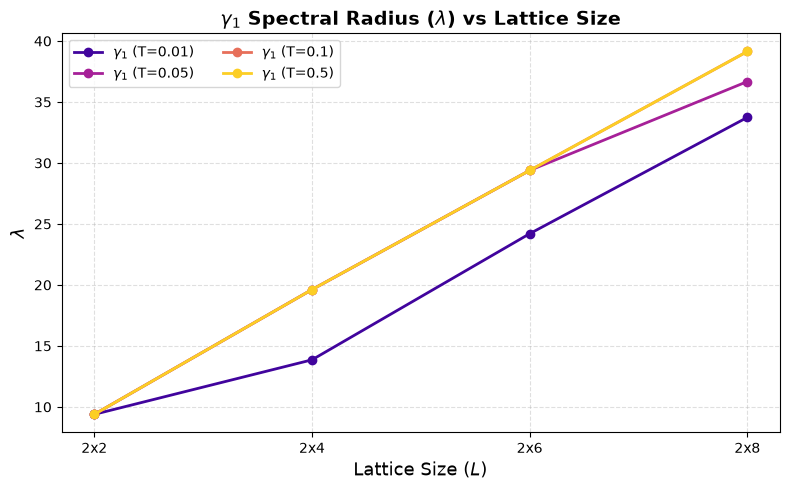

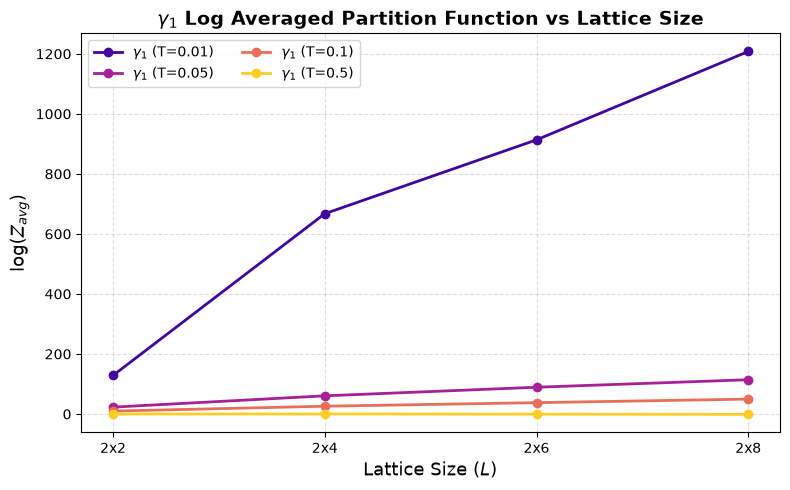

In [7]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eigh_tridiagonal
import scipy.sparse as sp
from scipy.special import logsumexp
from scipy.optimize import brentq
import itertools
import math
from joblib import dump, load
import time
from numba import njit, prange

# --- 0. Global Physical Constants ---
CONV_EV_TO_K = 11604.5 
t_phys_eV = 0.3         

# ---------------------------------------------------------
# 1. Basis & Matrix Generation (SINGLE SPIN ONLY)
# ---------------------------------------------------------
def generate_single_spin_basis(L, N_p):
    combos = itertools.combinations(range(L), N_p)
    basis = np.array([sum(1 << b for b in combo) for combo in combos], dtype=np.int64)
    state_to_idx = {state: idx for idx, state in enumerate(basis)}
    return basis, state_to_idx

def get_single_spin_matrix(Lx, Ly, t, tp, basis, state_to_idx, bc='PBC'):
    L = Lx * Ly
    dim = len(basis)
    rows, cols, data = [], [], []
    
    edges_nn, edges_nnn = set(), set()
    is_1d = (Lx == 1 or Ly == 1)
    
    for i in range(L):
        if is_1d:
            if bc == 'PBC' or i + 1 < L: edges_nn.add(tuple(sorted((i, (i + 1) % L))))
            if tp != 0.0 and (bc == 'PBC' or i + 2 < L): edges_nnn.add(tuple(sorted((i, (i + 2) % L))))
        else:
            x, y = i % Lx, i // Lx
            nx1, ny1 = (x + 1) % Lx, y
            nx2, ny2 = x, (y + 1) % Ly
            
            if bc == 'PBC' or (x + 1 < Lx): edges_nn.add(tuple(sorted((i, ny1 * Lx + nx1))))
            if bc == 'PBC' or (y + 1 < Ly): edges_nn.add(tuple(sorted((i, ny2 * Lx + nx2))))
                
            if tp != 0.0:
                nx3, ny3 = (x + 1) % Lx, (y + 1) % Ly
                nx4, ny4 = (x + 1) % Lx, (y - 1) % Ly
                if bc == 'PBC' or (x + 1 < Lx and y + 1 < Ly): edges_nnn.add(tuple(sorted((i, ny3 * Lx + nx3))))
                if bc == 'PBC' or (x + 1 < Lx and y - 1 >= 0): edges_nnn.add(tuple(sorted((i, ny4 * Lx + nx4))))
                
    edges_nn = [e for e in edges_nn if e[0] != e[1]]
    if tp != 0.0: edges_nnn = [e for e in edges_nnn if e[0] != e[1]]

    for idx, s in enumerate(basis):
        hopping_list = [(edges_nn, t)]
        if tp != 0.0: hopping_list.append((edges_nnn, tp))

        for edges, hop_val in hopping_list:
            if hop_val == 0.0: continue
            for i, j in edges:
                if ((s >> i) & 1) == 1 and ((s >> j) & 1) == 0:
                    s_new = s ^ (1 << i) ^ (1 << j)
                    idx_new = state_to_idx[s_new]
                    m1, m2 = min(i, j), max(i, j)
                    count = (s & ((1 << m2) - (1 << (m1 + 1)))).bit_count()
                    val = -hop_val * (1 if count % 2 == 0 else -1)
                    
                    rows.append(idx_new); cols.append(idx); data.append(val)
                    rows.append(idx); cols.append(idx_new); data.append(val)

    return sp.coo_matrix((data, (rows, cols)), shape=(dim, dim)).tocsr()
    
# --- Massively fast pre-computation of interaction energies ---
@njit(parallel=True, fastmath=True)
def build_U_diag_fast(U, up_basis, dn_basis):
    N_up = len(up_basis)
    N_dn = len(dn_basis)
    U_diag = np.zeros((N_up, N_dn), dtype=np.float64)
    for i in prange(N_up):
        u_state = up_basis[i]
        for j in range(N_dn):
            d_state = dn_basis[j]
            # Bitwise trick to count set bits (double occupancies)
            tmp = u_state & d_state
            c = 0
            while tmp > 0:
                tmp &= tmp - 1
                c += 1
            U_diag[i, j] = U * c
    return U_diag

def apply_relative_spectral_bias(evals, err_min, err_max):
    l_min, l_max = np.min(evals), np.max(evals)
    new_l_min = l_min * (1.0 + err_min)
    new_l_max = l_max * (1.0 + err_max)
    
    if np.isclose(l_max, l_min):
        biased_evals = evals * (1.0 + (err_min + err_max) / 2.0)
    else:
        fraction = (evals - l_min) / (l_max - l_min)
        biased_evals = new_l_min + fraction * (new_l_max - new_l_min)
    return biased_evals, np.max(np.abs([new_l_min, new_l_max]))
    
# ---------------------------------------------------------
# 2. Spectral Precomputation (Tensor Network Mat-Vec)
# ---------------------------------------------------------

@njit(parallel=True, fastmath=True)
def tensor_spmv(H_up_data, H_up_indices, H_up_indptr,
                H_dn_data, H_dn_indices, H_dn_indptr,
                U_diag, V, W):
    """
    Computes W = H_up * V + V * H_dn^T + U_diag * V with perfect cache locality.
    """
    N_up = V.shape[0]
    N_dn = V.shape[1]

    for u in prange(N_up):
        # 1. Diagonal U term + H_dn hopping (acts purely on down-spin index d)
        for d in range(N_dn):
            val = U_diag[u, d] * V[u, d]
            for p in range(H_dn_indptr[d], H_dn_indptr[d+1]):
                d_prime = H_dn_indices[p]
                val += H_dn_data[p] * V[u, d_prime]
            W[u, d] = val

        # 2. H_up hopping (acts purely on up-spin index u)
        for p in range(H_up_indptr[u], H_up_indptr[u+1]):
            u_prime = H_up_indices[p]
            hop = H_up_data[p]
            # Fast inner loop over contiguous memory
            for d in range(N_dn):
                W[u, d] += hop * V[u_prime, d]

def _compute_single_sample(H_up, H_dn, U_diag, N_tot, N_up, N_dn_dim, steps):
    v_1d = np.random.choice([-1.0, 1.0], size=N_tot)
    v_1d /= np.sqrt(N_tot)
    
    alpha, beta = np.zeros(steps), np.zeros(steps - 1)
    v_prev_1d = None
    v_curr_1d = v_1d
    
    # Pre-allocate W as a 1D array to avoid reallocation
    w_1d = np.zeros(N_tot, dtype=np.float64)
    
    for j in range(steps):
        # Create 2D views without copying memory
        V_2d = v_curr_1d.reshape((N_up, N_dn_dim))
        W_2d = w_1d.reshape((N_up, N_dn_dim))
        
        # --- Tensor Mat-Vec ---
        tensor_spmv(H_up.data, H_up.indices, H_up.indptr,
                    H_dn.data, H_dn.indices, H_dn.indptr,
                    U_diag, V_2d, W_2d)
        
        if v_prev_1d is not None: w_1d -= beta[j-1] * v_prev_1d
        alpha[j] = np.dot(v_curr_1d, w_1d)
        w_1d -= alpha[j] * v_curr_1d
        
        if j < steps - 1:
            beta[j] = np.linalg.norm(w_1d)
            if beta[j] < 1e-12: 
                alpha, beta = alpha[:j+1], beta[:j]; break
            v_prev_1d, v_curr_1d = v_curr_1d, w_1d / beta[j]
            
    evals, evecs = eigh_tridiagonal(alpha, beta)
    return evals, evecs[0, :]**2

def compute_sector_spectra_batched(H_up, H_dn, U_diag, Lx, Ly, N_up, N_dn, total_sample, sample_unit, steps, cache_dir):
    N_up_dim = H_up.shape[0]
    N_dn_dim = H_dn.shape[0]
    N_tot = N_up_dim * N_dn_dim
    
    # Exact Diagonalization Fallback for small matrices
    if N_tot <= 2000: 
        #print(f"      -> Exact Diagonalization used (Dim: {N_tot} <= 2000).")
        H_full = sp.kron(H_up, sp.eye(N_dn_dim)) + sp.kron(sp.eye(N_up_dim), H_dn) + sp.diags(U_diag.ravel())
        evals = np.linalg.eigvalsh(H_full.toarray())
        return 'exact', evals    

    sector_file = os.path.join(cache_dir, f"sector_{Lx}x{Ly}_up{N_up}_dn{N_dn}.joblib")
    
    if os.path.exists(sector_file):
        try:
            accumulated_samples = load(sector_file)
            #print(f"      -> Loaded {len(accumulated_samples)} samples from cache.")
        except (EOFError, ValueError):
            accumulated_samples = []
    else:
        accumulated_samples = []
        
    while len(accumulated_samples) < total_sample:
        remaining = total_sample - len(accumulated_samples)
        batch_size = min(sample_unit, remaining)
        
        batch_start = time.time()
        new_samples = []
        max_allowed_steps = min(steps, N_tot)
        
        for _ in range(batch_size):
            new_samples.append(_compute_single_sample(H_up, H_dn, U_diag, N_tot, N_up_dim, N_dn_dim, max_allowed_steps))
        
        accumulated_samples.extend(new_samples)
        dump(accumulated_samples, sector_file)
        
        batch_dur = time.time() - batch_start
        steps_taken = [len(samp[0]) for samp in new_samples]
        
        if batch_size == 1:
            print(f"      -> Sample {len(accumulated_samples)}/{total_sample} | Time: {batch_dur:.2f}s | Lanczos Steps: {steps_taken[0]} / {max_allowed_steps}")
        else:
            avg_steps = sum(steps_taken) / len(steps_taken)
            print(f"      -> Samples: {len(accumulated_samples):>3}/{total_sample} | Time: {batch_dur:.2f}s | Avg Lanczos Steps: {avg_steps:.1f} / {max_allowed_steps}")
        
    return 'ftlm', N_tot, accumulated_samples

def _compute_single_sector(Lx, Ly, t, tp, U, N_up, N_dn, total_sample, sample_unit, steps, bc, cache_dir):
    gen_start = time.time()
    
    # 1. Generate single-spin basis
    up_basis, up_state_to_idx = generate_single_spin_basis(Lx*Ly, N_up)
    dn_basis, dn_state_to_idx = generate_single_spin_basis(Lx*Ly, N_dn)
    
    # 2. Generate single-spin matrices
    H_up = get_single_spin_matrix(Lx, Ly, t, tp, up_basis, up_state_to_idx, bc)
    H_dn = get_single_spin_matrix(Lx, Ly, t, tp, dn_basis, dn_state_to_idx, bc)
    
    # 3. Generate Interaction Matrix
    U_diag = build_U_diag_fast(U, up_basis, dn_basis)
    
    gen_dur = time.time() - gen_start
    N_tot = len(up_basis) * len(dn_basis)
    #print(f"    [Dim: {N_tot:,}] Tensor Matrices generated in {gen_dur:.3f}s")
    
    res = compute_sector_spectra_batched(H_up, H_dn, U_diag, Lx, Ly, N_up, N_dn, total_sample, sample_unit, steps, cache_dir)
    return (N_up, N_dn), res

def precompute_all_sectors(Lx, Ly, t, tp, U, total_sample=400, sample_unit=100, steps=40, bc='PBC'):
    L = Lx * Ly
    cache_dir = f"cache_lanczos_{Lx}x{Ly}_t{t}_tp{tp}_U{U}"
    os.makedirs(cache_dir, exist_ok=True)
    
    pairs = [(u, d) for u in range(L+1) for d in range(u+1)]
    pairs.sort(key=lambda x: math.comb(L, x[0])*math.comb(L, x[1]), reverse=True)
    
    spectra = {}
    for u, d in pairs:
        #print(f"\n  -> Computing Sector: Up: {u}, Dn: {d}")
        _, res = _compute_single_sector(Lx, Ly, t, tp, U, u, d, total_sample, sample_unit, steps, bc, cache_dir)
        spectra[(u, d)] = res
        if u != d: spectra[(d, u)] = res
        
    return spectra

def create_biased_spectra(spectra_unbiased, err_min, err_max):
    biased_spectra = {}
    for sector, data in spectra_unbiased.items():
        if data[0] == 'exact':
            evals = data[1]
            biased_evals, _ = apply_relative_spectral_bias(evals, err_min, err_max)
            biased_spectra[sector] = ('exact', biased_evals)
        else:
            _, N, smp = data
            biased_smp = []
            for evals, w in smp:
                biased_evals, _ = apply_relative_spectral_bias(evals, err_min, err_max)
                biased_smp.append((biased_evals, w))
            biased_spectra[sector] = ('ftlm', N, biased_smp)
    return biased_spectra

# ---------------------------------------------------------
# 3. Log-Space Evaluation
# ---------------------------------------------------------
def evaluate_q_components_log_space(spectra_biased, spectra_unbiased, target_mu, Beta_array, L):
    sector_log_Zs_exact, sector_log_Q2s, sector_Nps = [], [], []
    
    # --- NEW: Tracking arrays for Q2 components ---
    sector_keys = []
    sector_radii = []
    sector_log_Zs_un = []
    
    # Track global bounds for Q1 (shifted by chemical potential)
    global_min_shifted = np.inf 
    global_max_shifted = -np.inf

    for (N_up, N_dn) in spectra_unbiased.keys():
        data_un = spectra_unbiased[(N_up, N_dn)]
        data_bi = spectra_biased[(N_up, N_dn)]
        
        N_p = N_up + N_dn  
        shift = target_mu * N_p
        dim_s = math.comb(L, N_up) * math.comb(L, N_dn)
        log_dim_s = np.log(dim_s)
        
        # --- 1. Biased Min, Max, Midpoint, and Spectral Radius ---
        if data_bi[0] == 'exact':
            evals_bi = data_bi[1]
            s_min_bi = np.min(evals_bi)
            s_max_bi = np.max(evals_bi)
        else:
            s_min_bi = min(np.min(e) for e, w in data_bi[2])
            s_max_bi = max(np.max(e) for e, w in data_bi[2])
            
        s_mid_bi = (s_max_bi + s_min_bi) / 2.0
        s_radius_bi = (s_max_bi - s_min_bi) / 2.0  # lambda for the sector
        
        global_min_shifted = min(global_min_shifted, s_min_bi - shift)
        global_max_shifted = max(global_max_shifted, s_max_bi - shift)

        # --- 2. Unbiased Exact Partition Function (Base Trace) ---
        if data_un[0] == 'exact':
            evals_un = data_un[1]
            s_min_un = np.min(evals_un)
            log_Z_sum_un = np.log(np.sum(np.exp(-Beta_array[..., None] * (evals_un - s_min_un)), axis=-1)) - Beta_array * s_min_un
        else:
            _, N, smp_un = data_un
            s_min_un = min(np.min(e) for e, w in smp_un)
            Z_sum_un = sum(np.sum(np.exp(-Beta_array[..., None]*(e - s_min_un))*w, axis=-1) for e, w in smp_un)
            log_Z_sum_un = np.log((N/len(smp_un)) * Z_sum_un) - Beta_array * s_min_un

        log_Z_grand_exact = Beta_array * shift + log_Z_sum_un
        sector_log_Zs_exact.append(log_Z_grand_exact)
        sector_Nps.append(N_p) 

        # --- 3. Compute Q2 using the Shifted Hamiltonian ---
        log_Z_sector_shifted = Beta_array * s_mid_bi + log_Z_sum_un
        log_Q2_sector = log_dim_s + Beta_array * s_radius_bi - log_Z_sector_shifted
        
        sector_log_Q2s.append(log_Q2_sector)
        
        # --- NEW: Store components for later retrieval ---
        sector_keys.append((N_up, N_dn))
        sector_radii.append(s_radius_bi)
        sector_log_Zs_un.append(log_Z_sum_un)

    N_sectors = len(spectra_unbiased)
    
    # --- 4. Aggregate Q2 ---
    stacked_Q2s = np.stack(sector_log_Q2s)
    log_Q2_avg_values = logsumexp(stacked_Q2s, axis=0) - np.log(N_sectors)
    log_Q2_max_values = np.max(stacked_Q2s, axis=0)
    
    # --- NEW: Identify the sector maximizing Q2 ---
    # Assuming Beta_array is 1D, we take the argmax along the sector axis (0)
    idx_max = np.argmax(stacked_Q2s, axis=0)
    best_idx = idx_max[0] # Extracts index for the given Beta
    max_k_kp = sector_keys[best_idx]
    max_q2_lambda = sector_radii[best_idx]
    max_q2_log_Z = sector_log_Zs_un[best_idx][0] # Extract scalar log(Z)
    
    # --- 5. Compute Q1 using Global Shifted Hamiltonian ---
    global_mid_shifted = (global_max_shifted + global_min_shifted) / 2.0
    global_radius_shifted = (global_max_shifted - global_min_shifted) / 2.0
    
    total_log_Z_grand_exact = logsumexp(np.stack(sector_log_Zs_exact), axis=0)
    
    log_Z_grand_shifted = Beta_array * global_mid_shifted + total_log_Z_grand_exact
    log_Q1 = L * np.log(4) + Beta_array * global_radius_shifted - log_Z_grand_shifted

    # --- 6. Density computation ---
    density_array = np.zeros_like(Beta_array)
    for log_Z_sect, N_p in zip(sector_log_Zs_exact, sector_Nps):
        prob = np.exp(log_Z_sect - total_log_Z_grand_exact)
        density_array += (N_p / L) * prob

    norm = 1.0 / (L * np.log(4))
    
    # --- NEW: Bundle the requested components with log-space averaging ---
    log_dim_max_sector = np.log(math.comb(L, max_k_kp[0]) * math.comb(L, max_k_kp[1]))
    
    components = {
        'q1_lambda': global_radius_shifted, 
        'q1_log_avg_Z': total_log_Z_grand_exact[0] - (L * np.log(4)),
        'q2_max_k_kp': max_k_kp,
        'q2_max_lambda': max_q2_lambda,
        'q2_max_log_avg_Z': max_q2_log_Z - log_dim_max_sector
    }

    return log_Q1 * norm, log_Q2_max_values * norm, log_Q2_avg_values * norm, density_array, components
    

def evaluate_gamma3(spectra_biased, spectra_unbiased, Beta_array, L, K):
    """
    Computes gamma_3 by dividing each sector's spectrum into K energy bins.
    """
    norm = 1.0 / (L * np.log(4))
    
    # Initialize the max log-cost array with negative infinity
    log_Q3_max_values = np.full_like(Beta_array, -np.inf, dtype=np.float64)

    for (N_up, N_dn) in spectra_unbiased.keys():
        data_un = spectra_unbiased[(N_up, N_dn)]
        data_bi = spectra_biased[(N_up, N_dn)]
        
        dim_s = math.comb(L, N_up) * math.comb(L, N_dn)
        log_dim_s = np.log(dim_s)

        # 1. Determine Global Sector Bounds (from biased spectra)
        if data_bi[0] == 'exact':
            evals_bi = data_bi[1]
            s_min_bi = np.min(evals_bi)
            s_max_bi = np.max(evals_bi)
        else:
            s_min_bi = min(np.min(e) for e, w in data_bi[2])
            s_max_bi = max(np.max(e) for e, w in data_bi[2])

        lambda_s = (s_max_bi - s_min_bi) / 2.0
        bin_width = (s_max_bi - s_min_bi) / K
        
        # Handle edge case where sector has only identical eigenvalues
        if bin_width == 0:
            bin_width = 1e-12 

        # 2. Iterate over the K bins
        for k in range(K):
            b_start = s_min_bi + k * bin_width
            b_end = s_min_bi + (k + 1) * bin_width
            mu_sk = s_min_bi + (k + 0.5) * bin_width  # Midpoint of the k-th bin

            # 3. Restrict Trace to the k-th bin (Projection \Pi_{s,k})
            if data_un[0] == 'exact':
                evals_un = data_un[1]
                evals_bi_ref = data_bi[1]
                
                # Include right edge for the very last bin
                if k == K - 1:
                    mask = (evals_bi_ref >= b_start) & (evals_bi_ref <= b_end + 1e-9)
                else:
                    mask = (evals_bi_ref >= b_start) & (evals_bi_ref < b_end)
                    
                evals_in_bin = evals_un[mask]
                
                if len(evals_in_bin) == 0:
                    continue  # Trace is 0, log is -inf, skip to next bin
                
                # Tr( e^{-\beta (H_{bin} - \mu_{s,k})} )
                diff = evals_in_bin - mu_sk
                term = -Beta_array[:, None] * diff[None, :]
                Z_sk = np.sum(np.exp(term), axis=1)
                
            else:
                _, N_dim, smp_un = data_un
                _, _, smp_bi = data_bi
                
                Z_sk = np.zeros_like(Beta_array, dtype=np.float64)
                
                for (e_un, w), (e_bi, _) in zip(smp_un, smp_bi):
                    if k == K - 1:
                        mask = (e_bi >= b_start) & (e_bi <= b_end + 1e-9)
                    else:
                        mask = (e_bi >= b_start) & (e_bi < b_end)
                        
                    e_in_bin = e_un[mask]
                    w_in_bin = w[mask]
                    
                    if len(e_in_bin) == 0:
                        continue
                        
                    diff = e_in_bin - mu_sk
                    term = -Beta_array[:, None] * diff[None, :]
                    
                    # Compute weighted exponentials
                    exp_terms = np.exp(term) * w_in_bin[None, :]
                    Z_sk += np.sum(exp_terms, axis=1)
                
                if np.all(Z_sk == 0):
                    continue
                    
                # Normalize FTLM trace estimator
                Z_sk *= (N_dim / len(smp_un))

            # 4. Compute log(Q3) for this specific bin
            with np.errstate(divide='ignore'):
                log_Z_sk = np.log(Z_sk)
            
            # \gamma_3 numerator exponent is \beta * \lambda_s / K
            log_Q3_sk = log_dim_s + Beta_array * (lambda_s / K) - log_Z_sk
            
            # 5. Maximize over all sectors and bins
            log_Q3_max_values = np.maximum(log_Q3_max_values, log_Q3_sk)
            
    return log_Q3_max_values * norm

    
    
# ---------------------------------------------------------
# 4. Main Execution
# ---------------------------------------------------------
if __name__ == "__main__":
    total_start_time = time.time()

    # ADDED (2,8) to the configs list
    lattice_configs = [(2,2), (2,4), (2,6), (2,8)] 
    L_labels = [f"{Lx}x{Ly}" for Lx, Ly in lattice_configs]
    L_values = [Lx * Ly for Lx, Ly in lattice_configs]

    t, tp, U = 1.0, -0.2, 8
    target_density = 1
    
    T_targets = np.array([1/100, 1/20, 1/10, 1/2])
    Beta_targets = 1.0 / T_targets 

    err_min, err_max = 0.005, 0.007

    results_q1 = {T: [] for T in T_targets}
    results_q_avg = {T: [] for T in T_targets}
    results_mu = {T: [] for T in T_targets}
    
    # --- NEW: Storage for Lambda and Log(Z_avg) ---
    results_q1_lambda = {T: [] for T in T_targets}
    results_q1_logZ = {T: [] for T in T_targets}
    results_q2_lambda = {T: [] for T in T_targets}
    results_q2_logZ = {T: [] for T in T_targets}

    print("NOTE: Numba will compile the parallel kernel during the first sector.")

    for (Lx, Ly) in lattice_configs:
        lattice_start_time = time.time()
        L = Lx * Ly
        print(f"\n=======================================================")
        print(f"Lattice {Lx}x{Ly} (L={L}) | Fixed Density = {target_density}")
        print(f"=======================================================")
        
        # --- NEW LOGIC: Load 2x8 data from disk, compute others on the fly ---
        if L == 16: # This targets the 2x8 lattice
            filename_2x8 = f"full_spectra_dict_{Lx}x{Ly}_t{t}_tp{tp}_U{U}_COMBINED.joblib"
            
            if os.path.exists(filename_2x8):
                print(f"--> Loading precomputed spectra for 2x8 from {filename_2x8}...")
                spectra_cache_unbiased = load(filename_2x8)
            else:
                print(f"[!] ERROR: {filename_2x8} not found. Ensure the file is in the same directory.")
                print("[!] Exiting script to prevent a massive 2x8 calculation from starting.")
                exit(1)
        
        else: # For 2x2, 2x4, 2x6
            TARGET_SAMPLES = 30
            SAMPLE_UNIT = 400
            print(f"--> Target Samples: {TARGET_SAMPLES} (Batched in chunks of {SAMPLE_UNIT})")
            
            spectra_cache_unbiased = precompute_all_sectors(
                Lx, Ly, t, tp, U, 
                total_sample=TARGET_SAMPLES, 
                sample_unit=SAMPLE_UNIT, 
                bc='PBC'
            )
        # ---------------------------------------------------------------------

        print(f"\n--> Applying biases: err_min={err_min}, err_max={err_max}")
        spectra_cache_biased = create_biased_spectra(spectra_cache_unbiased, err_min, err_max)

        for i, T_val in enumerate(T_targets):
            Beta = Beta_targets[i]
            
            def density_diff(mu_guess):
                    _, _, _, dens_arr, _ = evaluate_q_components_log_space(
                        spectra_cache_biased, spectra_cache_unbiased, mu_guess, np.array([Beta]), L
                    )
                    return dens_arr[0] - target_density

            mu_opt = brentq(density_diff, -10.0, 20)
                
            # Unpack the 5th returned variable containing the component dictionary
            q1_arr, q2_max_arr, q2_avg_arr, dens_arr_exact, comps = evaluate_q_components_log_space(
                spectra_cache_biased, spectra_cache_unbiased, mu_opt, np.array([Beta]), L
            )
            
            # --- Append main results (SWAPPED FOR GAMMA 1 <-> GAMMA 2) ---
            results_q1[T_val].append(q2_max_arr[0])       # Gamma 1 is now Sector Metrics (q2)
            results_q_avg[T_val].append(q1_arr[0])        # Gamma 2 is now Global Metrics (q1)
            results_mu[T_val].append(mu_opt)
            
            # --- Append component results for plotting (SWAPPED) ---
            results_q1_lambda[T_val].append(comps['q2_max_lambda'])
            results_q1_logZ[T_val].append(comps['q2_max_log_avg_Z'])
            results_q2_lambda[T_val].append(comps['q1_lambda'])
            results_q2_logZ[T_val].append(comps['q1_log_avg_Z'])
            
            print(f"  * T = {T_val:.3f} | Required mu (exact) = {mu_opt:.4f}")
            print(f"    -> Density evaluated (sanity check): {dens_arr_exact[0]:.4f}")
            
            # Print gamma_1 (Sector) and its components
            print(rf"    [Gamma 1] T^* (Max) = {q2_max_arr[0]:.6f}")
            print(f"      -> Maximizing Sector (k, k'): {comps['q2_max_k_kp']}")
            print(f"      -> lambda(H_sector): {comps['q2_max_lambda']:.6f}")
            print(f"      -> log( Tr(e^{{-beta H_sector}}) / dim_sector ): {comps['q2_max_log_avg_Z']:.6f}")
            
            # Print gamma_2 (Global) and its components
            print(rf"    [Gamma 2] T^* = {q1_arr[0]:.6f}")
            print(f"      -> lambda(H - mu N): {comps['q1_lambda']:.6f}")
            print(f"      -> log( Tr(e^{{-beta(H - mu N)}}) / 4^L ): {comps['q1_log_avg_Z']:.6f}")
            print("-" * 50)
            
    # =========================================================
    # PLOTTING
    # =========================================================
    colors = plt.cm.plasma(np.linspace(0.1, 0.9, len(T_targets)))

    # --- Figure 1: Gamma 1 Lambda vs Lattice Size ---
    fig_g1_lambda = plt.figure(figsize=(8, 5))
    for idx, T_val in enumerate(T_targets):
        c = colors[idx]
        T_label = f"T={T_val:.3g}"
        plt.plot(L_values, results_q1_lambda[T_val], marker='o', color=c, linewidth=2, 
                 label=rf"$\gamma_1$ ({T_label})")
    plt.title(rf'$\gamma_1$ Spectral Radius ($\lambda$) vs Lattice Size', fontsize=14, fontweight='bold')
    plt.xlabel('Lattice Size ($L$)', fontsize=13)
    plt.ylabel(r'$\lambda$', fontsize=13)
    plt.xticks(L_values, L_labels)
    plt.grid(True, which='both', linestyle='--', alpha=0.4)
    plt.legend(ncol=2, fontsize=10, loc='best')
    plt.tight_layout()
    
    
    # --- Figure 3: Gamma 1 Log Averaged Z vs Lattice Size ---
    fig_g1_z = plt.figure(figsize=(8, 5))
    for idx, T_val in enumerate(T_targets):
        c = colors[idx]
        T_label = f"T={T_val:.3g}"
        plt.plot(L_values, results_q1_logZ[T_val], marker='o', color=c, linewidth=2, 
                 label=rf"$\gamma_1$ ({T_label})")
    plt.title(rf'$\gamma_1$ Log Averaged Partition Function vs Lattice Size', fontsize=14, fontweight='bold')
    plt.xlabel('Lattice Size ($L$)', fontsize=13)
    plt.ylabel(r'$\log(Z_{avg})$', fontsize=13)
    plt.xticks(L_values, L_labels)
    plt.grid(True, which='both', linestyle='--', alpha=0.4)
    plt.legend(ncol=2, fontsize=10, loc='best')
    plt.tight_layout()

    # # =========================================================
    # # PLOTTING OVERVIEW COMMENTED OUT
    # # =========================================================
    # colors = plt.cm.plasma(np.linspace(0.1, 0.9, len(T_targets)))
    
    # fig1 = plt.figure(figsize=(10, 6))
    # for idx, T_val in enumerate(T_targets):
    #     c = colors[idx]
    #     T_label = f"T={T_val:.3g}"
            
    #     plt.plot(L_values, results_q1[T_val], marker='o', color=c, linewidth=3, 
    #              label=rf"$\gamma_1$ ({T_label})")
    #     plt.plot(L_values, results_q_avg[T_val], marker='s', color=c, linestyle='--', linewidth=2, alpha=0.8,
    #              label=rf"$\gamma_2$ ({T_label})")
    
    # plt.axhline(y=1.0, color='black', linestyle='-.', linewidth=2, label='Linear time ($y=1$)')
    # plt.title(rf'Scaling of Cost ($U = {U}t, t\' = {tp}t, t=1$)', fontsize=14, fontweight='bold')
    # plt.xlabel('Lattice Size ($L$)', fontsize=13)
    # plt.ylabel('Normalized Base-4 Exponent', fontsize=13)
    # plt.xticks(L_values, L_labels) 
    # plt.grid(True, which='both', linestyle='--', alpha=0.4)
    # plt.legend(ncol=2, fontsize=10, loc='best')
    # plt.tight_layout()

    # total_elapsed_sec = time.time() - total_start_time
    # print(f"\n=======================================================")
    # print(f"TOTAL EXECUTION TIME: {total_elapsed_sec:.2f} seconds ({total_elapsed_sec/60:.2f} minutes)")
    # print(f"=======================================================\n")
    
    # #fig1.savefig("U=8,n=0.875,highT.pdf", dpi=300, bbox_inches='tight')
    
    #plt.show()


TOTAL EXECUTION TIME: 43.73 seconds (0.73 minutes)



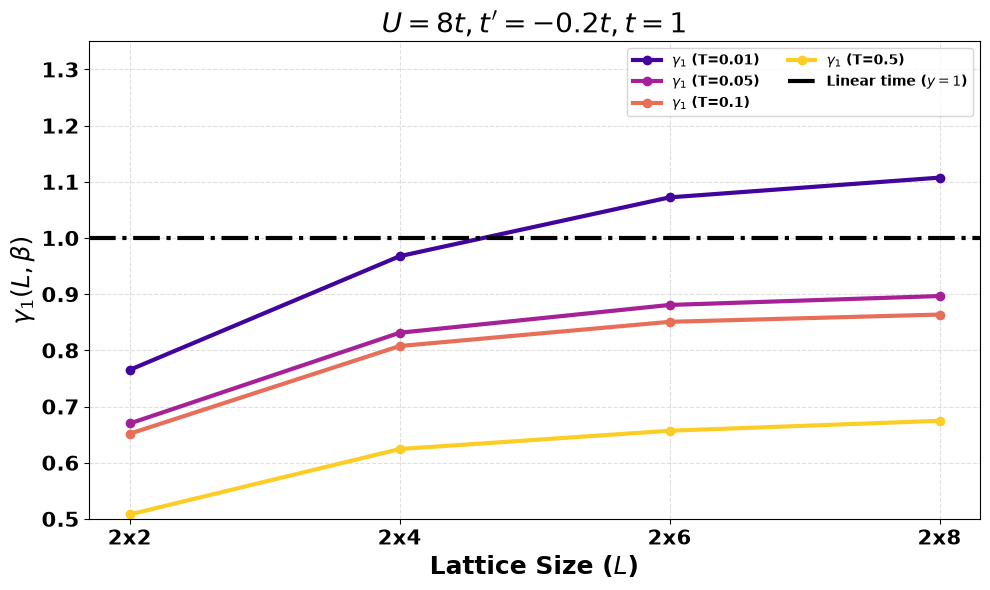

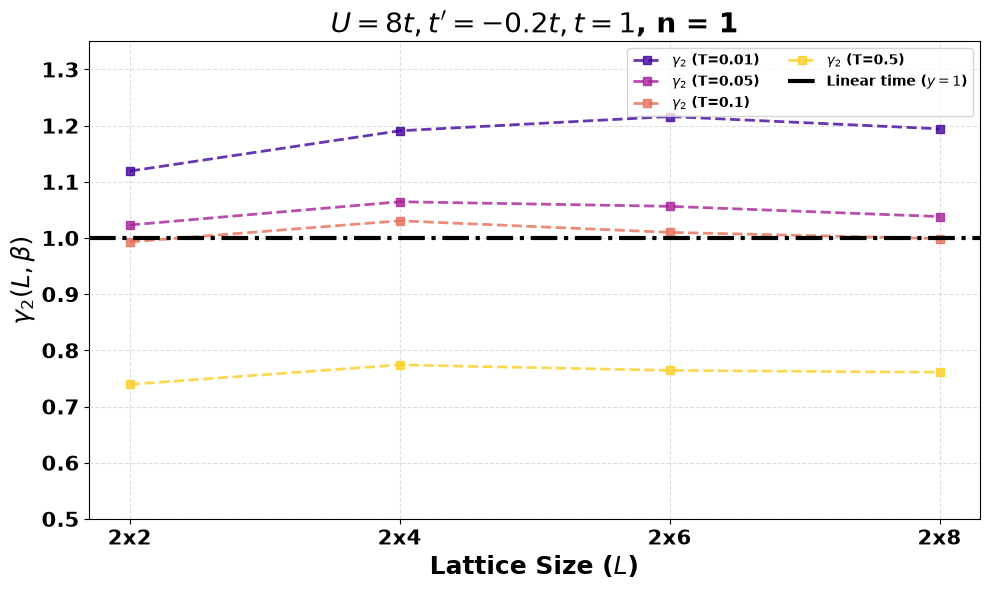

In [8]:
# =========================================================
# PLOTTING
# =========================================================
colors = plt.cm.plasma(np.linspace(0.1, 0.9, len(T_targets)))

# 1. Calculate global y-axis limits to synchronize both plots
all_y_data = [val for T in T_targets for val in results_q1[T]] + \
             [val for T in T_targets for val in results_q_avg[T]]

y_min, y_max = min(all_y_data), max(all_y_data)
y_margin = (y_max - y_min) * 0.05 if y_max != y_min else 0.1

# Ensure the y=1 reference line is always visible
plot_y_min = 0.5 #min(y_min - y_margin, 0.95)
plot_y_max = 1.35 #max(y_max + y_margin, 1.05)

# ---------------------------------------------------------
# Plot 1: Gamma 2
# ---------------------------------------------------------
fig1 = plt.figure(figsize=(10, 6))
for idx, T_val in enumerate(T_targets):
    c = colors[idx]
    T_label = f"T={T_val:.3g}"
        
    plt.plot(L_values, results_q1[T_val], marker='o', color=c, linewidth=3, 
             label=rf"$\gamma_1$ ({T_label})")

plt.axhline(y=1.0, color='black', linestyle='-.', linewidth=3, label='Linear time ($y=1$)')
plt.title(rf'$U = {U}t, t^\prime = {tp}t, t=1$', fontsize=20, fontweight='bold')
plt.xlabel('Lattice Size ($L$)', fontsize=18, fontweight='bold')
plt.ylabel(r'$\gamma_1(L,\beta)$', fontsize=18, fontweight='bold')

# Make tick labels bold and larger
plt.xticks(L_values, L_labels, fontweight='bold', fontsize=15) 
plt.yticks(fontweight='bold', fontsize=15)

plt.ylim(plot_y_min, plot_y_max)  # Apply global y-limits
plt.grid(True, which='both', linestyle='--', alpha=0.4)

# Make legend text bold
plt.legend(ncol=2, loc='best', prop={'size': 10, 'weight': 'bold'})
plt.tight_layout()
#fig1.savefig("gamma_1, U=4.pdf", dpi=300, bbox_inches='tight')

# ---------------------------------------------------------
# Plot 2: Gamma 1
# ---------------------------------------------------------
fig2 = plt.figure(figsize=(10, 6))
for idx, T_val in enumerate(T_targets):
    c = colors[idx]
    T_label = f"T={T_val:.3g}"
        
    plt.plot(L_values, results_q_avg[T_val], marker='s', color=c, linestyle='--', linewidth=2, alpha=0.8,
             label=rf"$\gamma_2$ ({T_label})")

plt.axhline(y=1.0, color='black', linestyle='-.', linewidth=3, label='Linear time ($y=1$)')
plt.title(rf'$U = {U}t, t^\prime = {tp}t, t=1$, n = {target_density}', fontsize=20, fontweight='bold')
plt.xlabel('Lattice Size ($L$)', fontsize=18, fontweight='bold')
plt.ylabel(r'$\gamma_2(L,\beta)$', fontsize=18, fontweight='bold')

# Make tick labels bold and larger
plt.xticks(L_values, L_labels, fontweight='bold', fontsize=15) 
plt.yticks(fontweight='bold', fontsize=15)

plt.ylim(plot_y_min, plot_y_max)  # Apply global y-limits
plt.grid(True, which='both', linestyle='--', alpha=0.4)

# Make legend text bold
plt.legend(ncol=2, loc='best', prop={'size': 10, 'weight': 'bold'})
plt.tight_layout()
fig2.savefig("gamma_2, U=8, n=1.pdf", dpi=300, bbox_inches='tight')

total_elapsed_sec = time.time() - total_start_time
print(f"\n=======================================================")
print(f"TOTAL EXECUTION TIME: {total_elapsed_sec:.2f} seconds ({total_elapsed_sec/60:.2f} minutes)")
print(f"=======================================================\n")

plt.show()